In [12]:
from collections import deque
from dataclasses import dataclass
import cv2
import numpy as np


@dataclass
class DetectionResult:
    found: bool
    distance_ft: float | None = None
    raw_distance_ft: float | None = None
    target_width_px: float = 0.0
    center_xy: tuple[int, int] | None = None
    roi_bbox: tuple[int, int, int, int] | None = None  # (x1, y1, x2, y2) in full-res coords
    roi_mask: np.ndarray | None = None                 # Binary mask inside the ROI crop


class PurpleTargetTracker:
    """
    Two-stage HSV + Pinhole Distance Estimator designed for Raspberry Pi Zero 2 W.
    Stage 1: Fast contour search on hardware-downscaled `lores` stream.
    Stage 2: High-precision pixel measurement on a small crop of the full-res `main` stream.
    """

    def __init__(
        self,
        focal_length_mm: float = 16.0,
        target_size_ft: float = 40.0,
        pixel_pitch_mm: float = 0.00155,  # Sony IMX477
        lores_scale: int = 4,
        hsv_lower: tuple[int, int, int] = (125, 60, 40),
        hsv_upper: tuple[int, int, int] = (165, 255, 255),
        smooth_window: int = 5,
    ):
        self.focal_length_mm = focal_length_mm
        self.target_size_ft = target_size_ft
        self.pixel_pitch_mm = pixel_pitch_mm
        self.lores_scale = lores_scale

        self.hsv_lower = np.array(hsv_lower, dtype=np.uint8)
        self.hsv_upper = np.array(hsv_upper, dtype=np.uint8)
        self.morph_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

        # Rolling median buffer to reject single-frame atmospheric shimmer
        self.dist_history: deque[float] = deque(maxlen=smooth_window)

    def reset_filter(self) -> None:
        self.dist_history.clear()

    def process_frame(self, lores_bgr: np.ndarray, main_bgr: np.ndarray) -> DetectionResult:
        full_h, full_w = main_bgr.shape[:2]

        # --- STAGE 1: Fast Search on Lores Stream (1014 x 760) ---
        hsv_lo = cv2.cvtColor(lores_bgr, cv2.COLOR_BGR2HSV)
        mask_lo = cv2.inRange(hsv_lo, self.hsv_lower, self.hsv_upper)
        mask_lo = cv2.morphologyEx(mask_lo, cv2.MORPH_OPEN, self.morph_kernel)

        contours_lo, _ = cv2.findContours(mask_lo, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not contours_lo:
            return DetectionResult(found=False)

        largest_lo = max(contours_lo, key=cv2.contourArea)
        if cv2.contourArea(largest_lo) < 4:  # Ignore tiny 1-2 px noise specks
            return DetectionResult(found=False)

        x_lo, y_lo, w_lo, h_lo = cv2.boundingRect(largest_lo)
        cx_full = int((x_lo + w_lo / 2.0) * self.lores_scale)
        cy_full = int((y_lo + h_lo / 2.0) * self.lores_scale)

        # --- STAGE 2: Crop Small ROI from Full-Res Buffer (4056 x 3040) ---
        half_roi = max(125, int(max(w_lo, h_lo) * self.lores_scale * 0.85))
        x1 = max(0, cx_full - half_roi)
        y1 = max(0, cy_full - half_roi)
        x2 = min(full_w, cx_full + half_roi)
        y2 = min(full_h, cy_full + half_roi)

        roi_bgr = main_bgr[y1:y2, x1:x2]
        hsv_roi = cv2.cvtColor(roi_bgr, cv2.COLOR_BGR2HSV)
        mask_roi = cv2.inRange(hsv_roi, self.hsv_lower, self.hsv_upper)

        contours_roi, _ = cv2.findContours(mask_roi, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not contours_roi:
            return DetectionResult(found=False)

        target_cnt = max(contours_roi, key=cv2.contourArea)
        area_px = cv2.contourArea(target_cnt)
        if area_px <= 0:
            return DetectionResult(found=False)

        # Equivalent side length from pixel area reduces +/- 1 px edge quantization jitter
        equiv_width_px = float(np.sqrt(area_px))

        # Pinhole projection formula: D = (f * W_real) / (w_px * pixel_pitch)
        raw_dist_ft = (self.focal_length_mm * self.target_size_ft) / (
            equiv_width_px * self.pixel_pitch_mm
        )
        self.dist_history.append(raw_dist_ft)
        smoothed_dist_ft = float(np.median(self.dist_history))

        return DetectionResult(
            found=True,
            distance_ft=smoothed_dist_ft,
            raw_distance_ft=raw_dist_ft,
            target_width_px=equiv_width_px,
            center_xy=(cx_full, cy_full),
            roi_bbox=(x1, y1, x2, y2),
            roi_mask=mask_roi,
        )

In [13]:
import cv2
import mujoco
import numpy as np

FT_TO_M = 0.3048


class MuJoCoTargetEnv:
    """
    Simulates a 40x40 ft purple target at 80 ft altitude, viewed from a ground-mounted
    Sony IMX477 camera with a 25 mm lens and configurable upward pitch angle.
    """

    SENSOR_W_PX = 4056
    SENSOR_H_PX = 3040
    PIXEL_PITCH_MM = 0.00155

    def __init__(
        self,
        focal_length_mm: float = 25.0,
        target_size_ft: float = 40.0,
        target_alt_ft: float = 80.0,
        camera_alt_ft: float = 5.0,   # Ground tripod height (set to 0.0 for ground surface)
        pitch_deg: float = 4.5,       # Upward tilt so 80 ft target stays in 10.8° VFOV
        lores_scale: int = 4,
    ):
        self.focal_length_mm = focal_length_mm
        self.target_size_m = target_size_ft * FT_TO_M
        self.target_alt_m = target_alt_ft * FT_TO_M
        self.camera_alt_m = camera_alt_ft * FT_TO_M
        self.pitch_deg = pitch_deg
        self.lores_scale = lores_scale

        sensor_h_mm = self.SENSOR_H_PX * self.PIXEL_PITCH_MM
        self.vfov_deg = float(2.0 * np.degrees(np.arctan((sensor_h_mm / 2.0) / focal_length_mm)))

        xml = self._build_xml()
        self.model = mujoco.MjModel.from_xml_string(xml)
        self.data = mujoco.MjData(self.model)
        self.cam_body_id = mujoco.mj_name2id(self.model, mujoco.mjtObj.mjOBJ_BODY, "cam_rig")
        self.renderer = mujoco.Renderer(
            self.model, height=self.SENSOR_H_PX, width=self.SENSOR_W_PX
        )

    def _build_xml(self) -> str:
        half_w = self.target_size_m / 2.0
        # Tilt camera's local +Y (up) axis backward by pitch_deg to look upward along -X
        a = np.radians(self.pitch_deg)
        xyaxes_str = f"0 1 0 {np.sin(a):.6f} 0 {np.cos(a):.6f}"

        return f"""
        <mujoco model="purple_target_world">
          <statistic extent="100"/>
          <visual>
            <global offwidth="{self.SENSOR_W_PX}" offheight="{self.SENSOR_H_PX}"/>
            <map znear="0.01" zfar="100"/>
            <rgba haze="0.75 0.85 0.95 1"/>
          </visual>

          <asset>
            <texture type="skybox" builtin="gradient" rgb1="0.45 0.68 0.95" rgb2="0.85 0.92 0.98" width="512" height="512"/>
            <texture name="ground_tex" type="2d" builtin="checker" rgb1="0.22 0.35 0.20" rgb2="0.26 0.40 0.23" width="512" height="512"/>
            <material name="ground_mat" texture="ground_tex" texrepeat="200 200"/>
          </asset>

          <worldbody>
            <light pos="500 -500 1000" dir="-0.4 0.4 -0.8" diffuse="0.9 0.9 0.9"/>
            <geom name="ground" type="plane" size="3000 3000 0.1" material="ground_mat"/>

            <!-- Vertical 40x40 ft purple panel at 80 ft altitude -->
            <body name="target" pos="0 0 {self.target_alt_m}">
              <geom name="purple_panel" type="box"
                    size="0.1 {half_w} {half_w}"
                    rgba="0.52 0.12 0.72 1.0"/>
            </body>

            <!-- Ground-mounted camera rig -->
            <body name="cam_rig" pos="1524 0 {self.camera_alt_m}">
              <camera name="hq_cam" fovy="{self.vfov_deg:.4f}" xyaxes="{xyaxes_str}"/>
            </body>
          </worldbody>
        </mujoco>
        """

    def capture_streams(
        self,
        distance_ft: float,
        lateral_offset_ft: float = 15.0,
        camera_alt_ft: float | None = None,
        haze_strength: float = 0.0,
        sensor_noise_std: float = 0.0,
    ) -> tuple[np.ndarray, np.ndarray]:
        alt_m = self.camera_alt_m if camera_alt_ft is None else camera_alt_ft * FT_TO_M
        self.model.body_pos[self.cam_body_id] = [
            distance_ft * FT_TO_M,
            lateral_offset_ft * FT_TO_M,
            alt_m,
        ]
        mujoco.mj_forward(self.model, self.data)

        self.renderer.update_scene(self.data, camera="hq_cam")
        rgb_full = self.renderer.render()
        main_bgr = cv2.cvtColor(rgb_full, cv2.COLOR_RGB2BGR)

        if haze_strength > 0.0:
            sky_haze = np.full_like(main_bgr, (235, 210, 190))
            main_bgr = cv2.addWeighted(main_bgr, 1.0 - haze_strength, sky_haze, haze_strength, 0)

        if sensor_noise_std > 0.0:
            noise = np.random.normal(0, sensor_noise_std, main_bgr.shape)
            main_bgr = np.clip(main_bgr.astype(np.float32) + noise, 0, 255).astype(np.uint8)

        lores_w = self.SENSOR_W_PX // self.lores_scale
        lores_h = self.SENSOR_H_PX // self.lores_scale
        lores_bgr = cv2.resize(main_bgr, (lores_w, lores_h), interpolation=cv2.INTER_AREA)

        return lores_bgr, main_bgr

In [17]:
import cv2
import numpy as np

def save_debug_view(
    lores_bgr: np.ndarray,
    result,
    lores_scale: int,
    true_dist_ft: float,
    filename: str = "debug_5000ft.png",
) -> None:
    """Draws the ROI box onto the lores view alongside the zoomed high-res binary mask."""
    vis = lores_bgr.copy()
    if result.found and result.roi_bbox is not None and result.roi_mask is not None:
        x1, y1, x2, y2 = [coord // lores_scale for coord in result.roi_bbox]
        cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), 2)
        label = f"True: {true_dist_ft:.0f}ft | Est: {result.distance_ft:.0f}ft ({result.target_width_px:.1f}px)"
        cv2.putText(vis, label, (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)

        mask_color = cv2.cvtColor(result.roi_mask, cv2.COLOR_GRAY2BGR)
        zoom_panel = cv2.resize(mask_color, (260, 260), interpolation=cv2.INTER_NEAREST)
        vis[20:280, vis.shape[1] - 280 : vis.shape[1] - 20] = zoom_panel

    cv2.imwrite(filename, vis)


def main():
    FOCAL_MM = 25.0

    env = MuJoCoTargetEnv(focal_length_mm=FOCAL_MM, camera_alt_ft=5.0, pitch_deg=4.5)
    tracker = PurpleTargetTracker(focal_length_mm=FOCAL_MM)

    # Tested down to 600 ft (closer than ~545 ft, the 80 ft target exits the top of a fixed 25 mm frame)
    test_distances_ft = [5000, 4000, 3000, 2000, 1500, 1000, 600]

    print(f"Simulating IMX477 + {FOCAL_MM}mm C-Mount Lens (VFOV: {env.vfov_deg:.2f} deg)\n")
    print(f"{'Ground Dist (ft)':>16} | {'Measured Px':>12} | {'Est Dist (ft)':>14} | {'Error (ft)':>11}")
    print("-" * 63)

    for dist_ft in test_distances_ft:
        tracker.reset_filter()

        haze = 0.20 * (dist_ft / 5000.0)
        for _ in range(5):
            lores_bgr, main_bgr = env.capture_streams(
                distance_ft=dist_ft,
                lateral_offset_ft=25.0,
                haze_strength=haze,
                sensor_noise_std=4.0,
            )
            res = tracker.process_frame(lores_bgr, main_bgr)

        if dist_ft == 5000:
            save_debug_view(lores_bgr, res, env.lores_scale, dist_ft, "debug_5000ft.png")

        if res.found and res.distance_ft is not None:
            # Convert 3D slant distance to flat horizontal ground distance
            horiz_est_ft = float(np.sqrt(max(0.0, res.distance_ft**2 - 75.0**2)))
            err_ft = horiz_est_ft - dist_ft
            print(f"{dist_ft:16.1f} | {res.target_width_px:12.2f} | {horiz_est_ft:14.1f} | {err_ft:+11.1f}")
        else:
            print(f"{dist_ft:16.1f} | {'LOST':>12} | {'N/A':>14} | {'N/A':>11}")


if __name__ == "__main__":
    main()

Simulating IMX477 + 25.0mm C-Mount Lens (VFOV: 10.77 deg)

Ground Dist (ft) |  Measured Px |  Est Dist (ft) |  Error (ft)
---------------------------------------------------------------
          5000.0 |       128.84 |         5007.3 |        +7.3
          4000.0 |       160.93 |         4008.0 |        +8.0
          3000.0 |       214.00 |         3013.8 |       +13.8
          2000.0 |       322.00 |         2002.2 |        +2.2
          1500.0 |       428.83 |         1502.6 |        +2.6
          1000.0 |       642.54 |         1001.3 |        +1.3
           600.0 |      1064.48 |          601.4 |        +1.4


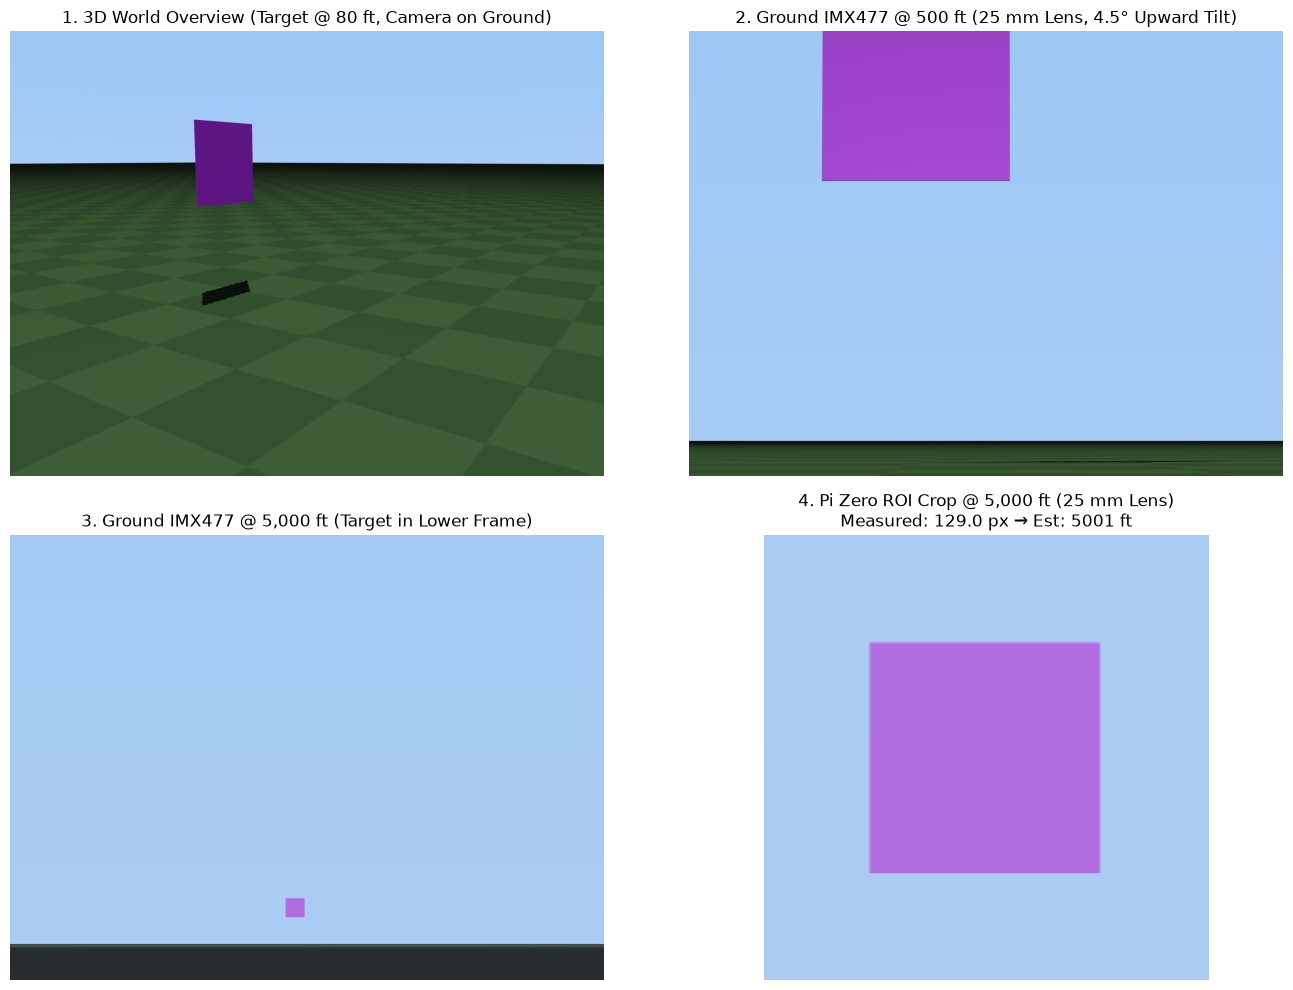

In [15]:
import cv2
import matplotlib.pyplot as plt
import mujoco

FT_TO_M = 0.3048

env = MuJoCoTargetEnv(focal_length_mm=25.0, camera_alt_ft=5.0, pitch_deg=4.5)
tracker = PurpleTargetTracker(focal_length_mm=25.0)

# --- 1. 3D World Overview ---
env.model.body_pos[env.cam_body_id] = [150.0 * FT_TO_M, 0.0, 5.0 * FT_TO_M]
mujoco.mj_forward(env.model, env.data)

overview_cam = mujoco.MjvCamera()
overview_cam.type = mujoco.mjtCamera.mjCAMERA_FREE
overview_cam.lookat = [15.0, 0.0, 12.0]
overview_cam.distance = 75.0
overview_cam.azimuth = 125.0
overview_cam.elevation = -10.0

env.renderer.update_scene(env.data, camera=overview_cam)
overview_rgb = env.renderer.render()

# --- 2. Ground Camera @ 500 ft (25 mm lens tilted 4.5° up) ---
lores_500, main_500 = env.capture_streams(distance_ft=500.0, lateral_offset_ft=15.0)
rgb_500 = cv2.cvtColor(main_500, cv2.COLOR_BGR2RGB)

# --- 3. Ground Camera @ 5,000 ft + Tracker ROI Crop ---
tracker.reset_filter()
lores_5000, main_5000 = env.capture_streams(
    distance_ft=5000.0, lateral_offset_ft=25.0, haze_strength=0.18
)
res_5000 = tracker.process_frame(lores_5000, main_5000)
rgb_5000 = cv2.cvtColor(main_5000, cv2.COLOR_BGR2RGB)

x1, y1, x2, y2 = res_5000.roi_bbox
roi_zoom_rgb = rgb_5000[y1:y2, x1:x2]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].imshow(overview_rgb)
axes[0, 0].set_title("1. 3D World Overview (Target @ 80 ft, Camera on Ground)")
axes[0, 0].axis("off")

axes[0, 1].imshow(rgb_500)
axes[0, 1].set_title("2. Ground IMX477 @ 500 ft (25 mm Lens, 4.5° Upward Tilt)")
axes[0, 1].axis("off")

axes[1, 0].imshow(rgb_5000)
axes[1, 0].set_title("3. Ground IMX477 @ 5,000 ft (Target in Lower Frame)")
axes[1, 0].axis("off")

axes[1, 1].imshow(roi_zoom_rgb)
axes[1, 1].set_title(
    f"4. Pi Zero ROI Crop @ 5,000 ft (25 mm Lens)\n"
    f"Measured: {res_5000.target_width_px:.1f} px → Est: {res_5000.distance_ft:.0f} ft"
)
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()

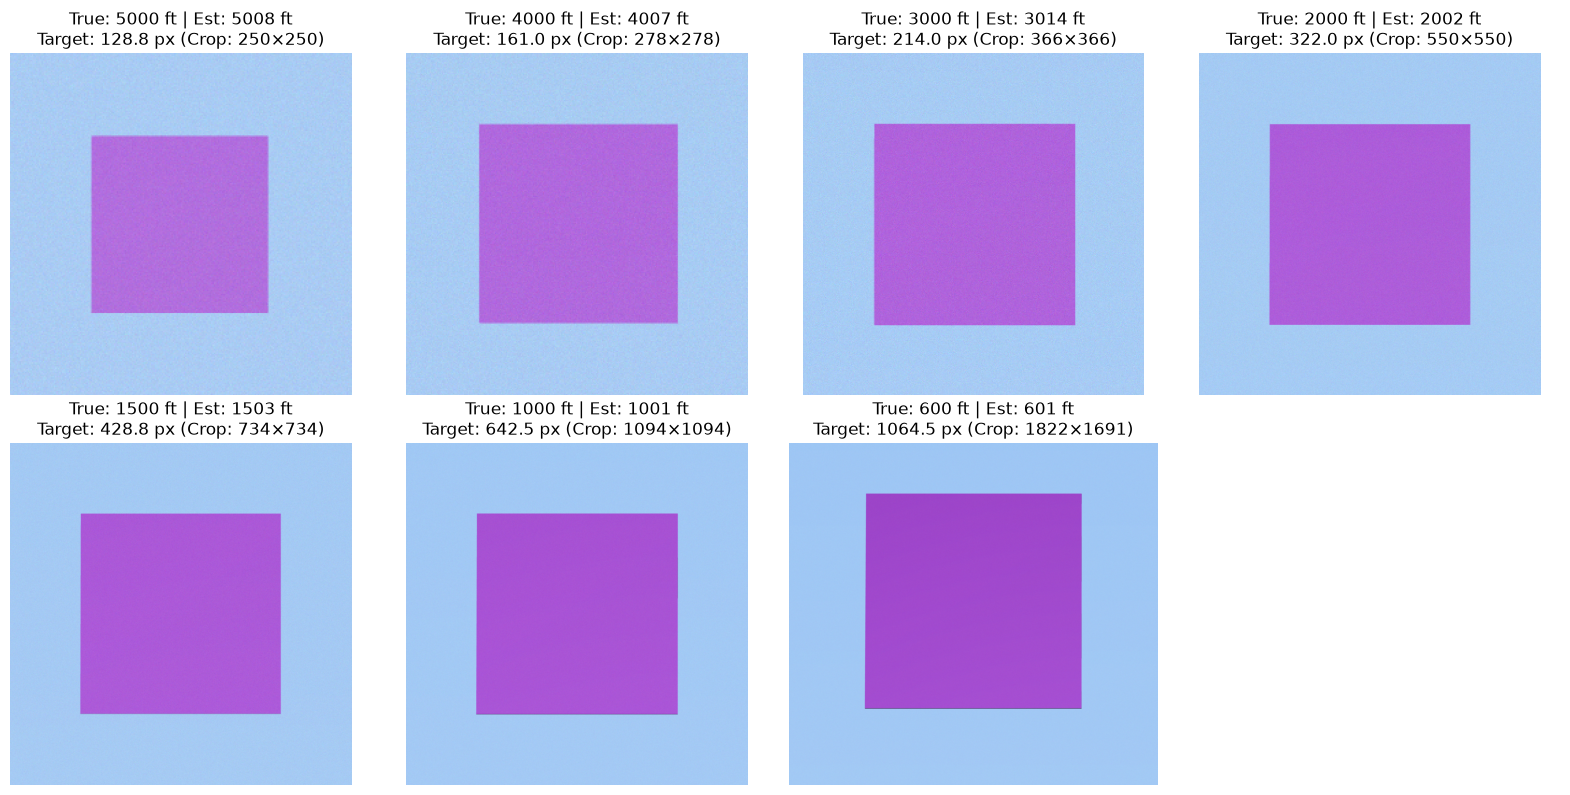

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

FOCAL_MM = 25.0
env = MuJoCoTargetEnv(focal_length_mm=FOCAL_MM, camera_alt_ft=5.0, pitch_deg=4.5)
tracker = PurpleTargetTracker(focal_length_mm=FOCAL_MM)

test_distances_ft = [5000, 4000, 3000, 2000, 1500, 1000, 600]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for idx, dist_ft in enumerate(test_distances_ft):
    ax = axes[idx]
    tracker.reset_filter()

    haze = 0.20 * (dist_ft / 5000.0)
    lores_bgr, main_bgr = env.capture_streams(
        distance_ft=dist_ft,
        lateral_offset_ft=25.0,
        haze_strength=haze,
        sensor_noise_std=4.0,
    )
    res = tracker.process_frame(lores_bgr, main_bgr)

    if res.found and res.roi_bbox is not None and res.distance_ft is not None:
        x1, y1, x2, y2 = res.roi_bbox
        crop_rgb = cv2.cvtColor(main_bgr[y1:y2, x1:x2], cv2.COLOR_BGR2RGB)
        horiz_est_ft = float(np.sqrt(max(0.0, res.distance_ft**2 - 75.0**2)))

        ax.imshow(crop_rgb)
        ax.set_title(
            f"True: {dist_ft} ft | Est: {horiz_est_ft:.0f} ft\n"
            f"Target: {res.target_width_px:.1f} px (Crop: {x2 - x1}×{y2 - y1})"
        )
    else:
        ax.text(0.5, 0.5, "LOST", ha="center", va="center", fontsize=14, color="red")
        ax.set_title(f"True: {dist_ft} ft")

    ax.axis("off")

# Hide the unused 8th subplot slot
for idx in range(len(test_distances_ft), len(axes)):
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

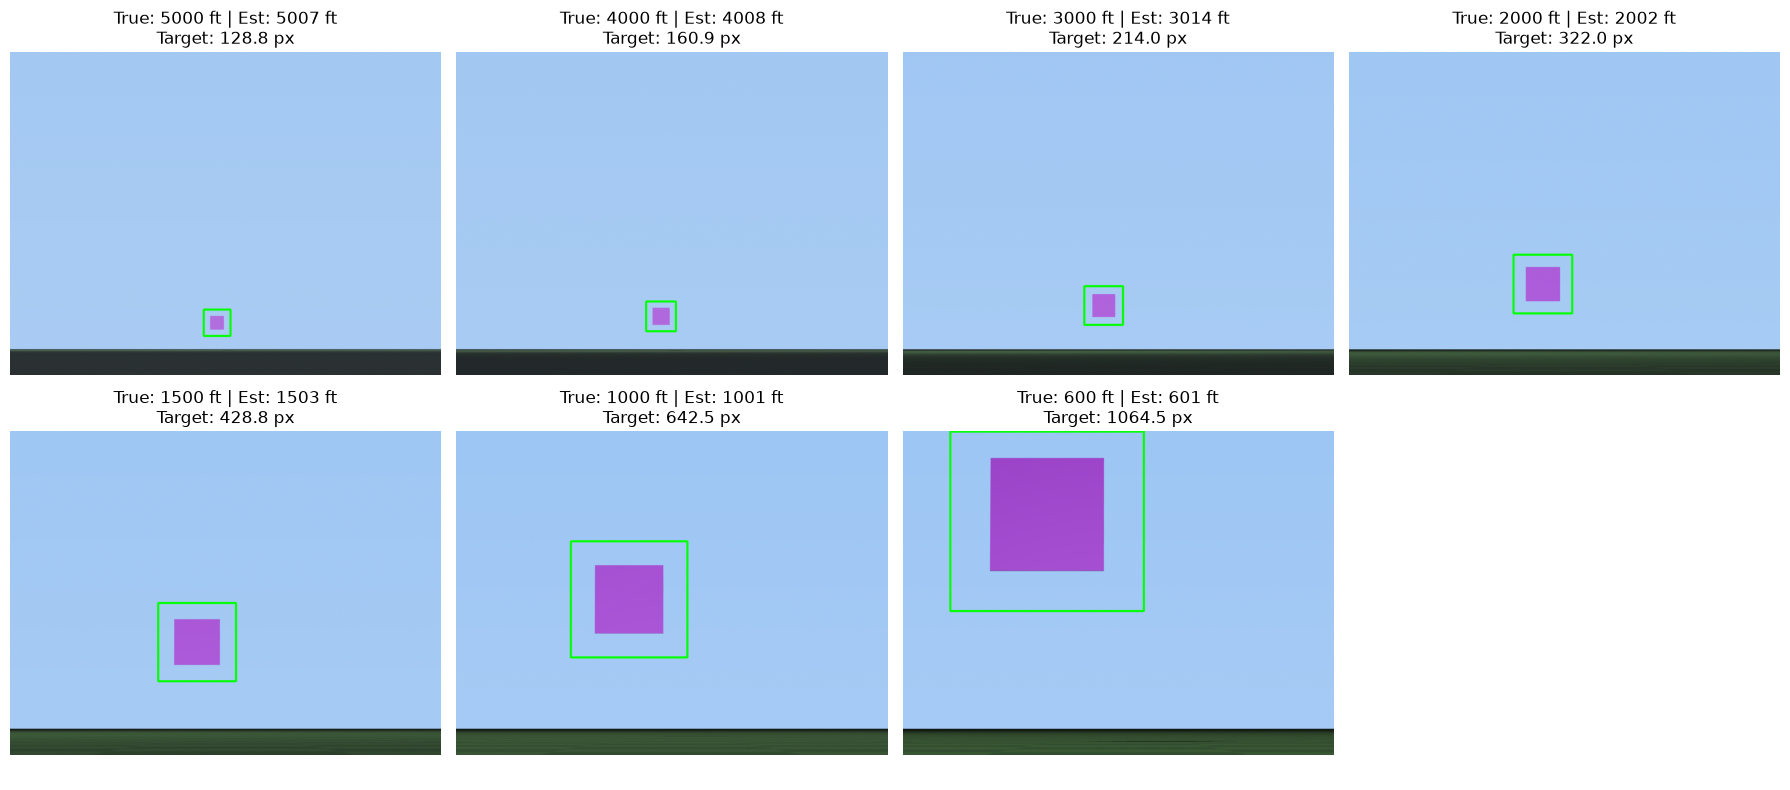

In [19]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

FOCAL_MM = 25.0
env = MuJoCoTargetEnv(focal_length_mm=FOCAL_MM, camera_alt_ft=5.0, pitch_deg=4.5)
tracker = PurpleTargetTracker(focal_length_mm=FOCAL_MM)

test_distances_ft = [5000, 4000, 3000, 2000, 1500, 1000, 600]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for idx, dist_ft in enumerate(test_distances_ft):
    ax = axes[idx]
    tracker.reset_filter()

    haze = 0.20 * (dist_ft / 5000.0)
    lores_bgr, main_bgr = env.capture_streams(
        distance_ft=dist_ft,
        lateral_offset_ft=25.0,
        haze_strength=haze,
        sensor_noise_std=4.0,
    )
    res = tracker.process_frame(lores_bgr, main_bgr)

    # Use the full-FOV lores frame (identical field of view to main, faster to plot)
    vis_bgr = lores_bgr.copy()

    if res.found and res.roi_bbox is not None and res.distance_ft is not None:
        x1, y1, x2, y2 = [c // env.lores_scale for c in res.roi_bbox]
        cv2.rectangle(vis_bgr, (x1, y1), (x2, y2), (0, 255, 0), 4)

        horiz_est_ft = float(np.sqrt(max(0.0, res.distance_ft**2 - 75.0**2)))
        ax.set_title(
            f"True: {dist_ft} ft | Est: {horiz_est_ft:.0f} ft\n"
            f"Target: {res.target_width_px:.1f} px"
        )
    else:
        ax.set_title(f"True: {dist_ft} ft (LOST)")

    ax.imshow(cv2.cvtColor(vis_bgr, cv2.COLOR_BGR2RGB))
    ax.axis("off")

# Hide the unused 8th subplot slot
for idx in range(len(test_distances_ft), len(axes)):
    axes[idx].axis("off")

plt.tight_layout()
plt.show()